# Are the pseudo-genres visible in how people listen? A co-listening graph check (RQ4)

## Background and question
This project studies the Yambda dataset (Yandex Music listening logs) and asks whether recommendations broaden or narrow what people listen to.
Yambda is anonymous: tracks have no titles and **no genre labels**. What a track *sounds like* is known only through a **128-dimensional audio embedding** per track.
To talk about "genres" we cluster these embeddings with spherical k-means and call each cluster a **pseudo-genre**.

**Research question 4:** are the pseudo-genres *real structure*, or an *artefact of the clustering*?
Clustering of the audio can only show structure *in sound*. This notebook uses an independent source, **how people listen**: it builds a **co-listening graph** (an edge between two tracks that users play in the same listening session) and asks:

> Are tracks of the same pseudo-genre connected in this graph more often than chance?

The graph never sees the audio and the pseudo-genres never see the graph, so agreement is evidence that the pseudo-genres correspond to something real in behaviour.
The measure is **modularity**: the share of edge weight that lies inside clusters, minus the share that random wiring would put there.

A convincing answer must survive three objections, which are handled explicitly:
1. *"It depends on k."* The number of pseudo-genres is a choice, so everything is repeated for k = 8, 16, 32 and 64.
2. *"It is only artist or album runs."* Tracks of one artist or album sound alike and are often played back to back. If most of the agreement came from such edges, it would say nothing about genres. We therefore **remove same-artist and same-album edges** and repeat the measurement.
3. *"It depends on which tracks and on the graph size."* We repeat the analysis on graphs with the 10,000, 20,000 and 40,000 most-listened tracks.

## Plan: what each step is for
| # | Step | What we want to learn |
|---|---|---|
| 1 | Pseudo-genres | the clusters to be tested, at four values of k and three random starts |
| 2 | The co-listening graph | a behaviour-only graph, and a check that it carries information about sound |
| 3 | Modularity of the pseudo-genres | do pseudo-genres follow the graph more than chance? |
| 4 | Controls: artist and album edges | does the result survive without artist and album runs? |
| 5 | Sensitivity to graph size | does it depend on which tracks are included? |
| 6 | Summary | answer and limitations |

*Prerequisites:* the processed embeddings `data/processed/emb50m_*.npy` (created by `scripts/extract_embeddings_50m.py`), the raw Yambda-50M events and the artist and album mappings in `data/raw/yambda/`.
Run time: roughly 10 minutes. Memory: below 3 GB.

## 0. Setup and parameters

In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
from scipy import sparse, stats
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

# ---------------- parameters (change here, then Run All) ----------------
ORGANIC_ONLY = True        # graph from listens the user chose (is_organic = 1); see section 2.1
REAL_PCT = 50              # a real listen = at least this % of the track played
SESSION_GAP_S = 30 * 60    # a gap longer than this starts a new session
BASKET_CAP = 15            # max distinct tracks per session used to form pairs
MAX_BASKETS_PER_USER = 50
N_NODES_LIST = [10_000, 20_000, 40_000]   # graph sizes: the most-listened tracks (with an embedding) become nodes
N_MAIN = 20_000            # the graph size used for the main results
MIN_COUNT = 3              # an edge needs at least this many sessions containing both tracks
K_NN = 20                  # each track keeps its K_NN strongest neighbours
K_GRID = [8, 16, 32, 64]   # numbers of pseudo-genres
K_MAIN = 32
N_SEEDS = 3
N_FIT = 150_000            # tracks used to fit k-means
N_SHUFFLE = 20             # label shuffles for the chance level of modularity
SEED = 42

rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
REAL, NULL, ACC = "#264653", "#9aa0a6", "#e76f51"

ROOT = Path.cwd()
while not (ROOT / "data" / "raw" / "yambda").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Could not find data/raw/yambda above " + str(Path.cwd()))
    ROOT = ROOT.parent
DATA, PROC, OUT = ROOT / "data" / "raw" / "yambda", ROOT / "data" / "processed", ROOT / "RQ4_extension"
print("project root:", ROOT)

project root: C:\MSc DTU\Semester 3\01. CTDS\Music


## 1. The pseudo-genres

**Method.** Spherical k-means on the audio embeddings (each scaled to unit length): every track is assigned to the centroid with the highest cosine similarity, each centroid is the re-normalised mean of its members, and the initial centres are chosen by k-means++ (each new centre is drawn with probability proportional to its squared distance from the centres already chosen, which spreads them out).
Cosine geometry is the natural choice for embeddings, where direction (what kind of sound) matters and length does not.

**What we fit.** The centroids are fitted on a random sample of 150,000 of the 848k embedded tracks (enough for stable centroids and much faster), and then **every** track is assigned to its nearest centroid, so the pseudo-genre of any track in the graph is defined independently of the graph.
We use k = 8, 16, 32, 64 and three random starts for each, because k-means depends on its start and the conclusion should not hinge on one run.

In [2]:
from sklearn.metrics import adjusted_rand_score
def spherical_kmeans(X, k, seed, n_iter=60):
    r = np.random.default_rng(seed); n_ = len(X)
    C = np.empty((k, X.shape[1]), dtype=np.float32); C[0] = X[r.integers(n_)]
    dist = 1 - X @ C[0]
    for j in range(1, k):                                   # k-means++ seeding with cosine distance
        pr = np.maximum(dist, 0) ** 2; C[j] = X[r.choice(n_, p=pr / pr.sum())]
        dist = np.minimum(dist, 1 - X @ C[j])
    labels = np.full(n_, -1)
    for _ in range(n_iter):
        new = np.argmax(X @ C.T, axis=1)
        if (new == labels).mean() > 0.9995:
            labels = new; break
        labels = new
        sums = csr_matrix((np.ones(n_, np.float32), (labels, np.arange(n_))), shape=(k, n_)) @ X
        nrm = np.linalg.norm(sums, axis=1, keepdims=True)
        empty = nrm[:, 0] == 0
        sums[empty] = X[r.integers(n_, size=empty.sum())]; nrm[empty] = 1
        C = (sums / np.maximum(nrm, 1e-9)).astype(np.float32)
    return C, labels

t0 = time.time()
emb_ids = np.load(PROC / "emb50m_item_ids.npy")
EN = np.load(PROC / "emb50m_norm.npy")                       # (848k, 128), unit length
fit_idx = rng.choice(len(EN), N_FIT, replace=False)
cent = {(k, s): spherical_kmeans(EN[fit_idx], k, SEED + 100 * s)[0] for k in K_GRID for s in range(N_SEEDS)}
def assign_all(Cn):
    out = np.empty(len(EN), dtype=np.int16)
    for s0 in range(0, len(EN), 200_000): out[s0:s0 + 200_000] = np.argmax(EN[s0:s0 + 200_000] @ Cn.T, axis=1)
    return out
pg = {key: assign_all(Cn) for key, Cn in cent.items()}      # pseudo-genre of every embedded track (indexed by embedding row)
stab = pd.DataFrame([dict(k=k, ari=np.mean([adjusted_rand_score(pg[(k, a)], pg[(k, b)]) for a in range(N_SEEDS) for b in range(a + 1, N_SEEDS)])) for k in K_GRID])
print(f"{len(cent)} k-means fits and assignments of {len(EN):,} tracks ({time.time() - t0:.0f} s)")
print("agreement between random starts (ARI, all tracks):", {int(r_.k): round(r_.ari, 2) for r_ in stab.itertuples()})

12 k-means fits and assignments of 847,921 tracks (37 s)
agreement between random starts (ARI, all tracks): {8: 0.59, 16: 0.62, 32: 0.58, 64: 0.66}


## 2. The co-listening graph

### 2.1 Design choices, and why
**What an edge means.** Two tracks are connected when the same user plays both **within the same listening session** (a session ends after a 30-minute gap). This is a behavioural signal of "these belong together" that does not depend on sound.

**Why organic listening only.** Each listen in Yambda is flagged *organic* (the user chose it) or *recommended*. The recommender may itself use audio similarity, so a graph built from recommended listens could mirror the recommender's notion of similarity and make our check partly circular.
Organic listens reflect users' own choices, which makes the graph a more independent source.

**Why only the most-listened tracks.** The graph needs enough co-listens per track to form reliable edges, and rarely played tracks have too few. Restricting to the top 10,000 to 40,000 tracks also keeps the computation feasible. The price is a *popularity bias*: results describe well-known tracks, not the long tail (section 5 shows how the result changes with the size).

**Edge weights and thinning.** Raw co-occurrence counts are dominated by hits. We divide the number of sessions containing both tracks by the square root of the product of their individual session counts (a cosine-type normalisation), drop pairs with fewer than 3 shared sessions (too noisy), keep each track's 20 strongest neighbours (an edge is kept if either endpoint selects it), and keep the largest connected component.

In [3]:
t0 = time.time()
flt = [("event_type", "=", "listen"), ("played_ratio_pct", ">=", REAL_PCT)]
if ORGANIC_ONLY: flt.append(("is_organic", "=", 1))
tbl = pq.read_table(DATA / "flat/50m/multi_event.parquet", columns=["uid", "item_id", "timestamp"], filters=flt)
uid = tbl["uid"].to_numpy().astype(np.int64); item = tbl["item_id"].to_numpy().astype(np.int64); ts = tbl["timestamp"].to_numpy().astype(np.int64)
del tbl
order = np.lexsort((ts, uid)); uid, item, ts = uid[order], item[order], ts[order]; del order
print(f"{len(uid):,} {'organic ' if ORGANIC_ONLY else ''}real listens of {len(np.unique(uid)):,} users ({time.time() - t0:.0f} s)")

L = int(max(item.max(), emb_ids.max())) + 1
item_row = np.full(L, -1, dtype=np.int64); item_row[emb_ids] = np.arange(len(emb_ids))
new_sess = np.r_[True, uid[1:] != uid[:-1]] | np.r_[True, (ts[1:] - ts[:-1]) > SESSION_GAP_S]
sid = np.cumsum(new_sess) - 1
pair = np.unique(uid * (1 << 32) + item)
users_per_item = np.bincount(pair & 0xFFFFFFFF, minlength=L); del pair
cand = np.flatnonzero((item_row >= 0) & (users_per_item > 0))
print(f"{sid[-1] + 1:,} sessions; {len(cand):,} tracks have an embedding and listens")

def first_map(path, col):
    mp = pd.read_parquet(path).drop_duplicates("item_id"); arr = np.full(L, -1, dtype=np.int64)
    ids = mp["item_id"].to_numpy(); ok = ids < L; arr[ids[ok]] = mp[col].to_numpy()[ok]; return arr
item_art = first_map(DATA / "artist_item_mapping.parquet", "artist_id")
item_alb = first_map(DATA / "album_item_mapping.parquet", "album_id")

14,121,730 organic real listens of 8,798 users (4 s)


1,457,671 sessions; 448,445 tracks have an embedding and listens


In [4]:
def rank_in_sorted_groups(g):
    start = np.r_[0, np.flatnonzero(g[1:] != g[:-1]) + 1]
    return np.arange(len(g)) - np.repeat(start, np.diff(np.r_[start, len(g)]))

def build_graph(n_nodes):
    top = cand[np.argsort(-users_per_item[cand], kind="stable")[:n_nodes]]
    node_of_item = np.full(L, -1, dtype=np.int64); node_of_item[top] = np.arange(len(top))
    nd = node_of_item[item]; m = nd >= 0
    s_, n_, u_ = sid[m], nd[m], uid[m]
    _, first = np.unique(s_ * len(top) + n_, return_index=True); first.sort()      # each track once per session, in order of play
    s_, n_, u_ = s_[first], n_[first], u_[first]
    keep = rank_in_sorted_groups(s_) < BASKET_CAP
    s_, n_, u_ = s_[keep], n_[keep], u_[keep]
    _, binv, bcnt = np.unique(s_, return_inverse=True, return_counts=True)
    b_user = u_[np.r_[0, np.cumsum(bcnt)[:-1]]]
    ok2 = bcnt >= 2                                                                   # baskets with at least 2 tracks
    rk_u = np.full(len(bcnt), 10 ** 9); rk_u[ok2] = rank_in_sorted_groups(b_user[ok2])
    ent = (ok2 & (rk_u < MAX_BASKETS_PER_USER))[binv]                                 # at most MAX_BASKETS_PER_USER per user
    rows = np.unique(binv[ent], return_inverse=True)[1]; cols = n_[ent]
    S = sparse.csr_matrix((np.ones(len(rows), np.float32), (rows, cols)), shape=(rows.max() + 1, len(top)))
    Cc = (S.T @ S).tocsr(); b = Cc.diagonal().copy(); Cc.setdiag(0); Cc.eliminate_zeros()
    Cc.data[Cc.data < MIN_COUNT] = 0; Cc.eliminate_zeros()
    co = Cc.tocoo(); w = co.data / np.sqrt(b[co.row] * b[co.col])
    o = np.lexsort((-w, co.row)); r_o, c_o, w_o = co.row[o], co.col[o], w[o]
    kk = rank_in_sorted_groups(r_o) < K_NN
    Wk = sparse.coo_matrix((w_o[kk], (r_o[kk], c_o[kk])), shape=Cc.shape).tocsr()
    A_full = Wk.maximum(Wk.T).tocsr()
    ncomp, comp = connected_components(A_full, directed=False)
    lcc = np.flatnonzero(comp == np.argmax(np.bincount(comp)))
    A = A_full[lcc][:, lcc].tocsr(); node_item = top[lcc]
    return dict(A=A, node_item=node_item, node_row=item_row[node_item], baskets=S.shape[0], candidates=len(top))

graphs = {}
for n_nodes in N_NODES_LIST:
    t1 = time.time(); graphs[n_nodes] = build_graph(n_nodes); g_ = graphs[n_nodes]; dg = g_["A"].getnnz(axis=1)
    print(f"{n_nodes:>6,} candidate tracks: {g_['A'].shape[0]:,} nodes in the largest component, {g_['A'].nnz // 2:,} edges, {g_['baskets']:,} baskets, median degree {np.median(dg):.0f} ({time.time() - t1:.0f} s)")
G = graphs[N_MAIN]; A, node_item, node_row = G["A"], G["node_item"], G["node_row"]; n = A.shape[0]

10,000 candidate tracks: 9,979 nodes in the largest component, 119,980 edges, 293,605 baskets, median degree 23 (3 s)


20,000 candidate tracks: 19,646 nodes in the largest component, 207,207 edges, 304,774 baskets, median degree 20 (3 s)


40,000 candidate tracks: 35,392 nodes in the largest component, 304,142 edges, 312,341 baskets, median degree 18 (4 s)


### 2.2 Does the graph carry information about sound?
**Why.** Before using the graph as a check on sound-based clusters we should confirm that it is not noise. If co-listening reflects musical similarity, **connected tracks should be closer in sound than random pairs**. The check is repeated after removing same-artist and same-album edges (section 4),
because those are the edges where a relation to sound is most expected.

**What we do.** We compare the audio cosine similarity of a sample of connected pairs with that of random pairs and summarise the difference with an AUC (0.5 = indistinguishable, 1 = perfectly separated).

In [5]:
def edge_audio_auc(Am, rows_, n_pairs=100_000):
    ei, ej = sparse.triu(Am, 1).nonzero()
    pick = rng.choice(len(ei), min(n_pairs, len(ei)), replace=False)
    ce = np.einsum("ij,ij->i", EN[node_row[ei[pick]]], EN[node_row[ej[pick]]])
    a_, b_ = rng.integers(0, Am.shape[0], n_pairs), rng.integers(0, Am.shape[0], n_pairs)
    cr = np.einsum("ij,ij->i", EN[node_row[a_]], EN[node_row[b_]])
    rk = stats.rankdata(np.r_[ce, cr]); auc = (rk[:len(ce)].sum() - len(ce) * (len(ce) + 1) / 2) / (len(ce) * len(cr))
    return auc, ce.mean(), cr.mean()
auc_all, mce, mcr = edge_audio_auc(A, node_row)
print(f"main graph ({n:,} tracks): mean audio cosine of connected pairs {mce:.3f} vs random pairs {mcr:.3f}; AUC {auc_all:.3f} (0.5 = no relation to sound)")

main graph (19,646 tracks): mean audio cosine of connected pairs 0.553 vs random pairs 0.158; AUC 0.877 (0.5 = no relation to sound)


### 2.3 Reading the graph check

**The pseudo-genres.** Two random starts of the k-means agree only partly (ARI between 0.58 and 0.66 for the four values of k), which is why every result below is averaged over three starts and reported with its spread.

**The graph.** The main graph has 19,646 tracks and 207,207 edges, with a median of 20 neighbours per track (354 of the 20,000 candidate tracks, 1.8%, lie outside the largest connected component and are dropped). The graphs with 10,000 and 40,000 candidate tracks have 9,979 and 35,392 tracks.

**It is related to sound.** Connected tracks have a mean audio cosine similarity of 0.55, random pairs 0.16; the AUC is **0.88** (0.5 would mean no relation). Nobody told the graph anything about audio, so co-listening reflects musical similarity.
The relation is far from perfect (not 1.0), and part of it comes from same-artist and same-album edges, which section 4 removes.

## 3. Modularity of the pseudo-genres

**Quantity.** For a partition of the nodes into clusters, with $A$ the weighted adjacency matrix, $2m=\sum A$ the total edge weight (counted from both ends), $e_{cc}$ the weight inside cluster $c$ and $d_c$ its total degree:
$$Q=\sum_c\Big[\frac{e_{cc}}{2m}-\Big(\frac{d_c}{2m}\Big)^2\Big].$$
The first term is the share of edge weight that falls inside clusters, the second what random wiring with the same degrees would put there. $Q=0$ means the clusters are no better than random labels, and larger values mean the clusters follow the graph.

**Chance level.** Modularity depends on the number and sizes of the clusters, so the proper reference is the **same partition with the labels shuffled** (cluster sizes preserved). We shuffle 20 times and report the mean, and a z-score (distance of the real value from the shuffled mean in shuffled standard deviations).

**What we want to learn.** Whether sound-based pseudo-genres follow co-listening more than chance, at each k, and how large the effect is. For a sense of scale: modularity values around 0.3 to 0.7 are typical of graphs with clear community structure; this is a rule of thumb, not a test.

main graph (19,646 tracks), all edges; mean over 3 k-means starts:
       Q  Q_sd  inside_share  expected_inside  Q_shuffled       z
k                                                                
8  0.520 0.009         0.680            0.160      -0.000 529.127
16 0.508 0.014         0.609            0.101      -0.000 592.585
32 0.480 0.005         0.537            0.057      -0.000 691.676
64 0.433 0.006         0.465            0.032      -0.000 889.938


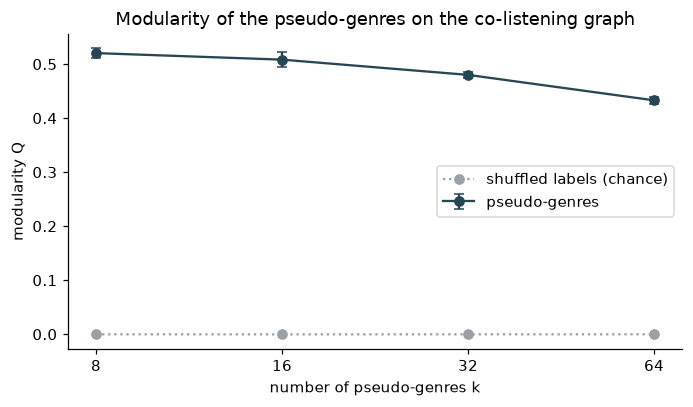

In [6]:
def modularity_parts(Am, lab, k):
    M = csr_matrix((np.ones(len(lab)), (np.arange(len(lab)), lab)), shape=(len(lab), k))
    Bm = (M.T @ Am @ M).toarray(); tot = Bm.sum()
    inside = np.trace(Bm) / tot; expected = ((Bm.sum(1) / tot) ** 2).sum()
    return inside, expected

def evaluate(Am, node_row_, graph_label, variant):
    rows = []
    for k in K_GRID:
        for s in range(N_SEEDS):
            lab = pg[(k, s)][node_row_].astype(np.int64)
            ins, exp_ = modularity_parts(Am, lab, k)
            sh = [np.subtract(*modularity_parts(Am, rng.permutation(lab), k)) for _ in range(N_SHUFFLE)]
            Q = ins - exp_
            rows.append(dict(graph=graph_label, variant=variant, k=k, seed=s, Q=Q, inside=ins, expected=exp_, Q_shuffled=np.mean(sh), Q_shuffled_sd=np.std(sh) + 1e-12,
                             z=(Q - np.mean(sh)) / (np.std(sh) + 1e-12)))
    return rows

res = pd.DataFrame(evaluate(A, node_row, N_MAIN, "all edges"))
tab = res.groupby("k").agg(Q=("Q", "mean"), Q_sd=("Q", "std"), inside_share=("inside", "mean"), expected_inside=("expected", "mean"), Q_shuffled=("Q_shuffled", "mean"), z=("z", "mean"))
print(f"main graph ({n:,} tracks), all edges; mean over {N_SEEDS} k-means starts:")
print(tab.to_string(float_format=lambda x: f"{x:.3f}"))
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.errorbar(tab.index, tab["Q"], yerr=tab["Q_sd"], fmt="o-", color=REAL, capsize=3, label="pseudo-genres")
ax.plot(tab.index, tab["Q_shuffled"], "o:", color=NULL, label="shuffled labels (chance)")
ax.set(title="Modularity of the pseudo-genres on the co-listening graph", xlabel="number of pseudo-genres k", ylabel="modularity Q"); ax.set_xscale("log")
ax.set_xticks(K_GRID); ax.set_xticklabels(K_GRID); ax.minorticks_off(); ax.legend()
plt.tight_layout(); plt.show()

### 3.1 Reading the modularity

**The pseudo-genres follow co-listening far more than chance, at every k.** At k = 32 the modularity is **0.48** (spread over three k-means starts 0.005), against 0.000 for shuffled labels; 54% of the edge weight lies inside pseudo-genres where random labels would put 6%, a factor of 9.

| k | 8 | 16 | 32 | 64 |
|---|---|---|---|---|
| Modularity Q | 0.52 | 0.51 | 0.48 | 0.43 |
| Share of edge weight inside pseudo-genres | 68% | 61% | 54% | 47% |
| Same, expected by chance | 16% | 10% | 6% | 3% |
| Ratio to chance | 4.3 | 6.0 | 9.4 | 14.5 |

**Why Q falls as k grows, and why this is not weaker structure.** With more, smaller clusters, more edges necessarily cross cluster boundaries, so Q decreases. Relative to chance the effect grows with k (ratio 4.3 to 14.5): even 64 small pseudo-genres keep 47% of the edge weight inside.

**On the z-scores.** The values in the table (hundreds) mean only that the real modularity lies far outside the range of shuffled labels, whose spread is tiny with 20,000 nodes. They are not a measure of the size of the effect; Q and the ratio to chance are.
For orientation, modularity of 0.3 to 0.7 is usually read as clear community structure in a graph (a rule of thumb, not a test). What we did **not** compute is the highest modularity any partition of this graph could reach, so we cannot say what fraction of the listening structure the pseudo-genres capture, only that they capture a lot.

## 4. Controls: are the results just artist and album runs?

**Why.** An artist's tracks, and an album's tracks, sound alike and are often played back to back. Such edges would connect same-pseudo-genre tracks even if listening had nothing to do with genre beyond the artist or album.
If most of the modularity came from them, the check would not support the claim that pseudo-genres match *listening behaviour* in general.

**What we do.** We recompute the modularity after **removing from the graph** (a) edges between tracks of the same artist, (b) edges between tracks of the same album, and (c) both. Tracks with no artist or album information keep their edges. We first measure how much of the graph the removed edges make up.
The pseudo-genres are unchanged; the chance level is recomputed for each reduced graph.

**What we want to learn.** How much of the modularity survives. If a large part does, pseudo-genres match listening between *different* artists and albums, which is what a genre-like structure means.

edges of the main graph that join tracks of the same artist or album:
                      share of edges  share of edge weight
same artist                    0.301                 0.466
same album                     0.063                 0.138
same artist or album           0.304                 0.474


drop same-artist edges: 144,879 edges left; 

drop same-album edges: 194,165 edges left; 

drop same-artist or same-album edges: 144,198 edges left; 

modularity Q:
k                                       8     16    32    64
variant                                                     
all edges                            0.520 0.508 0.480 0.433
drop same-artist edges               0.400 0.373 0.327 0.268
drop same-album edges                0.500 0.484 0.448 0.399
drop same-artist or same-album edges 0.396 0.370 0.325 0.266

z-score against shuffled labels:
k                                     8   16  32   64
variant                                              
all edges                            529 593 692  890
drop same-artist edges               335 398 421  541
drop same-album edges                493 641 684 1055
drop same-artist or same-album edges 370 434 483  437

Q retained relative to all edges:
k                                      8    16   32   64
variant                                                 
all edges                            1.00 1.00 1.00 1

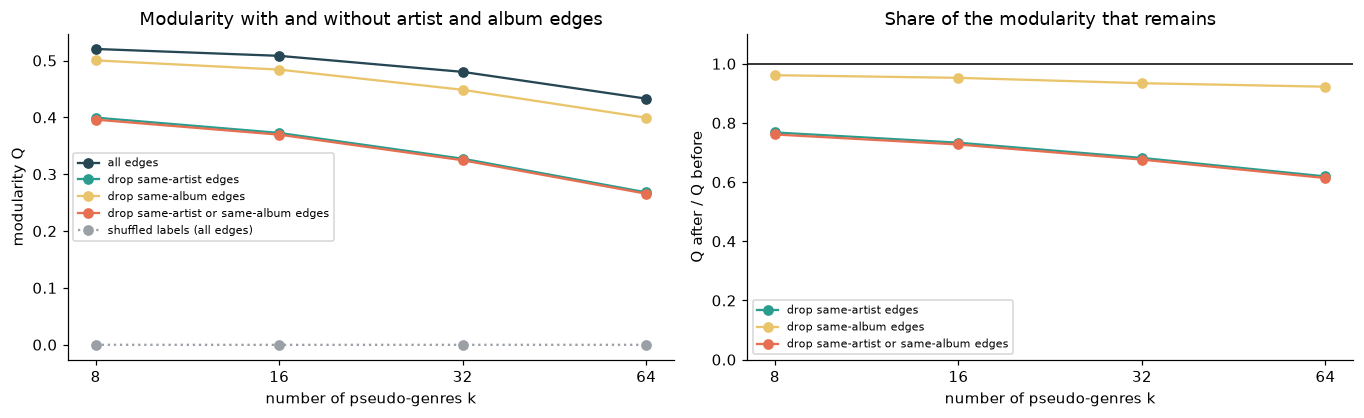

In [7]:
rr, cc = A.nonzero(); wv = np.asarray(A[rr, cc]).ravel()
a_i, a_j = item_art[node_item[rr]], item_art[node_item[cc]]; b_i, b_j = item_alb[node_item[rr]], item_alb[node_item[cc]]
same_art = (a_i == a_j) & (a_i >= 0); same_alb = (b_i == b_j) & (b_i >= 0)
diag = pd.DataFrame({"share of edges": [same_art.mean(), same_alb.mean(), (same_art | same_alb).mean()],
                     "share of edge weight": [wv[same_art].sum() / wv.sum(), wv[same_alb].sum() / wv.sum(), wv[same_art | same_alb].sum() / wv.sum()]},
                    index=["same artist", "same album", "same artist or album"])
print("edges of the main graph that join tracks of the same artist or album:"); print(diag.to_string(float_format=lambda x: f"{x:.3f}"))

def drop(mask):
    keep = ~mask
    return sparse.coo_matrix((wv[keep], (rr[keep], cc[keep])), shape=A.shape).tocsr()
variants = {"drop same-artist edges": drop(same_art), "drop same-album edges": drop(same_alb), "drop same-artist or same-album edges": drop(same_art | same_alb)}
ctrl = [res]
for name, Av in variants.items():
    ctrl.append(pd.DataFrame(evaluate(Av, node_row, N_MAIN, name)))
    print(f"{name}: {Av.nnz // 2:,} edges left", end="; ")
ctrl = pd.concat(ctrl); print()
cq = ctrl.groupby(["variant", "k"]).agg(Q=("Q", "mean"), Q_shuffled=("Q_shuffled", "mean"), z=("z", "mean")).reset_index()
order_v = ["all edges"] + list(variants)
piv_q = cq.pivot(index="variant", columns="k", values="Q").loc[order_v]; piv_z = cq.pivot(index="variant", columns="k", values="z").loc[order_v]
print("\nmodularity Q:"); print(piv_q.to_string(float_format=lambda x: f"{x:.3f}"))
print("\nz-score against shuffled labels:"); print(piv_z.to_string(float_format=lambda x: f"{x:.0f}"))
print("\nQ retained relative to all edges:"); print((piv_q / piv_q.loc["all edges"]).to_string(float_format=lambda x: f"{x:.2f}"))
auc_ctrl, _, _ = edge_audio_auc(variants["drop same-artist or same-album edges"], node_row)
print(f"\nAUC of audio similarity, connected vs random pairs: all edges {auc_all:.3f}, after dropping same-artist/album edges {auc_ctrl:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12.5, 3.9))
cols_v = [REAL, "#2a9d8f", "#e9c46a", ACC]
for (name, c) in zip(order_v, cols_v): ax[0].plot(piv_q.columns, piv_q.loc[name], "o-", color=c, label=name)
ax[0].plot(piv_q.columns, cq[cq.variant == "all edges"].set_index("k")["Q_shuffled"], "o:", color=NULL, label="shuffled labels (all edges)")
ax[0].set(title="Modularity with and without artist and album edges", xlabel="number of pseudo-genres k", ylabel="modularity Q"); ax[0].legend(fontsize=7)
ret = piv_q / piv_q.loc["all edges"]
for (name, c) in zip(order_v[1:], cols_v[1:]): ax[1].plot(ret.columns, ret.loc[name], "o-", color=c, label=name)
ax[1].axhline(1, color="k", lw=1); ax[1].set(title="Share of the modularity that remains", xlabel="number of pseudo-genres k", ylabel="Q after / Q before", ylim=(0, 1.1)); ax[1].legend(fontsize=7)
for a_ in ax: a_.set_xscale("log"); a_.set_xticks(K_GRID); a_.set_xticklabels(K_GRID); a_.minorticks_off()
plt.tight_layout(); plt.show()

### 4.1 Reading the controls

**The control matters.** In the main graph **30% of the edges and 47% of the edge weight** join tracks of the same artist; same-album edges are 6% of the edges and 14% of the weight and are almost all also same-artist edges (artist or album together: 30% of the edges, 47% of the weight).
Almost half of the weight is therefore artist runs, exactly the kind of edge that could produce agreement without any link to genre.

**Most of the modularity survives their removal.** Without same-artist and same-album edges the modularity is **0.40, 0.37, 0.33 and 0.27** for k = 8, 16, 32, 64, i.e. **76%, 73%, 68% and 61%** of the original values, again against about 0 for shuffled labels.
At k = 32, 0.33 of the 0.48 remains: about a third of the original modularity was artist and album structure, and two thirds is co-listening *between different artists and albums* that follows the pseudo-genres. The share retained falls slowly with k (finer pseudo-genres are closer to artist level, so more of their agreement is lost when artist edges are removed).
Removing album edges alone changes little (92% to 96% retained) because album edges are mostly also artist edges.

**The remaining edges are still related to sound** (AUC 0.83 against 0.88 for all edges), so the graph without artist runs still connects sound-similar tracks.

**How to read it.** The pseudo-genres match listening behaviour across artists, which is what a genre-like structure means, not only artist loyalty. The control removes the artist and album information that the dataset records; it cannot remove other shared attributes that are not in the data (same label, same era, same collaboration circle).

## 5. Sensitivity to the graph size

**Why.** The graph contains the most-listened tracks only. If the result depended strongly on how many tracks we include, we could not say whether it describes music in general or just the best-known tracks.

**What we do.** We repeat the modularity calculation (all edges, and without same-artist or same-album edges) on the graphs with the 10,000, 20,000 and 40,000 most-listened tracks.

**What we want to learn.** Whether the modularity and the share that survives the controls are stable across sizes.

k = 16:
variant  all edges  drop same-artist or same-album edges  share retained
graph                                                                   
10000        0.499                                 0.371           0.743
20000        0.508                                 0.370           0.727
40000        0.522                                 0.380           0.728
k = 32:
variant  all edges  drop same-artist or same-album edges  share retained
graph                                                                   
10000        0.478                                 0.335           0.701
20000        0.480                                 0.325           0.676
40000        0.489                                 0.329           0.674
k = 64:
variant  all edges  drop same-artist or same-album edges  share retained
graph                                                                   
10000        0.430                                 0.270           0.627
20000        0.433         

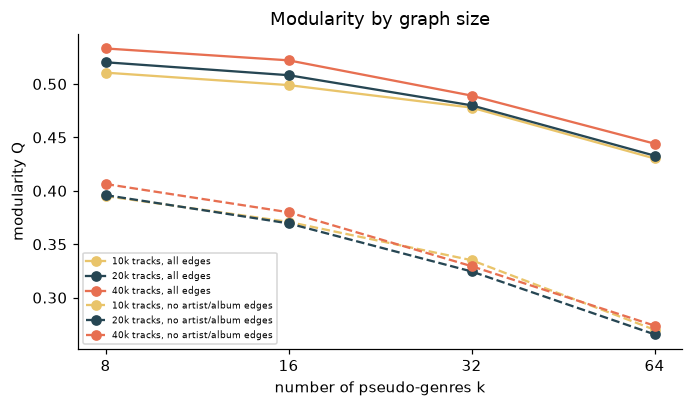

wrote RQ4_extension/graph_check_results.csv


In [8]:
sens = []
for n_nodes, g_ in graphs.items():
    if n_nodes == N_MAIN:
        sens.append(res.assign(graph=n_nodes)); sens.append(ctrl[ctrl.variant == "drop same-artist or same-album edges"].assign(graph=n_nodes)); continue
    Ag = g_["A"]; r2, c2 = Ag.nonzero(); w2 = np.asarray(Ag[r2, c2]).ravel(); ni = g_["node_item"]
    sa = (item_art[ni[r2]] == item_art[ni[c2]]) & (item_art[ni[r2]] >= 0); sb = (item_alb[ni[r2]] == item_alb[ni[c2]]) & (item_alb[ni[r2]] >= 0); kp = ~(sa | sb)
    Ad = sparse.coo_matrix((w2[kp], (r2[kp], c2[kp])), shape=Ag.shape).tocsr()
    sens.append(pd.DataFrame(evaluate(Ag, g_["node_row"], n_nodes, "all edges"))); sens.append(pd.DataFrame(evaluate(Ad, g_["node_row"], n_nodes, "drop same-artist or same-album edges")))
sens = pd.concat(sens)
st = sens.groupby(["graph", "variant", "k"]).agg(Q=("Q", "mean"), z=("z", "mean")).reset_index()
for k in [16, 32, 64]:
    pv = st[st.k == k].pivot(index="graph", columns="variant", values="Q")
    pv["share retained"] = pv["drop same-artist or same-album edges"] / pv["all edges"]
    print(f"k = {k}:"); print(pv.to_string(float_format=lambda x: f"{x:.3f}"))
fig, ax = plt.subplots(figsize=(6.4, 3.8))
for (var, ls) in [("all edges", "-"), ("drop same-artist or same-album edges", "--")]:
    for n_nodes, c in zip(N_NODES_LIST, ["#e9c46a", REAL, ACC]):
        d = st[(st.graph == n_nodes) & (st.variant == var)]; ax.plot(d["k"], d["Q"], "o" + ls, color=c, label=f"{n_nodes // 1000}k tracks, {'all edges' if var == 'all edges' else 'no artist/album edges'}")
ax.set(title="Modularity by graph size", xlabel="number of pseudo-genres k", ylabel="modularity Q"); ax.set_xscale("log"); ax.set_xticks(K_GRID); ax.set_xticklabels(K_GRID); ax.minorticks_off(); ax.legend(fontsize=6)
plt.tight_layout(); plt.show()
OUT.mkdir(exist_ok=True)
st.to_csv(OUT / "graph_check_results.csv", index=False)
print("wrote RQ4_extension/graph_check_results.csv")

### 5.1 Reading the sensitivity

The result is stable across graph size. At k = 32 the modularity with all edges is 0.478, 0.480 and 0.489 for the graphs with the 10,000, 20,000 and 40,000 most-listened candidate tracks, and the share retained after the control is 70%, 68% and 67%; at k = 16 it is 74%, 73% and 73%, at k = 64 63%, 61% and 62%.
Differences between sizes are at most 0.02 in Q and 3 percentage points in the retained share, much smaller than the effect itself. Including more tracks (down to less well-known ones) neither weakens nor strengthens the result within this range, although even the largest graph contains only the best-known tracks.

## 6. Summary and limitations

**Answer for RQ4, behavioural side.** The sound-based pseudo-genres are **visible in how people listen**: for every k from 8 to 64, a large share of the co-listening weight lies inside pseudo-genres (54% at k = 32 against 6% for shuffled labels; modularity 0.48 against 0). The graph never saw the audio, so this is evidence that the pseudo-genres are not only an artefact of clustering sound.
About a third of that agreement at k = 32 is artist and album runs; **two thirds (modularity 0.33) remains when same-artist and same-album edges are removed**, and the result is stable across graph size and across k-means starts.

**Limitations.**
- *Popular tracks only.* Nodes are the 10,000 to 40,000 most-listened tracks; results describe well-known tracks, not the long tail.
- *Organic listening only, one sample.* The graph uses users' own choices from 8,798 users of Yambda-50M. A graph from recommended listens would reflect the recommender and might behave differently. Sessions use a 30-minute gap, baskets are capped at 15 tracks and 50 per user, edges need 3 shared sessions and 20 neighbours per track; none of these settings was varied.
- *An aggregate effect, not a pairwise one.* Modularity says that, overall, more weight than chance lies inside pseudo-genres; it does not mean every co-listened pair shares a pseudo-genre (46% of the weight at k = 32 does not).
- *No upper reference.* We did not compute the highest attainable modularity, so we cannot say what fraction of the listening structure the pseudo-genres capture.
- *The control covers recorded metadata only* (artist and album), not label, era or other shared attributes.
- *One clustering method* (spherical k-means) with three starts per k; the starts agree only partly (ARI 0.58 to 0.66), so statements about single clusters are fragile and aggregate statements are safer.
- *Associations only*, in Yambda-50M.